Image dimensions: 1440 x 1440


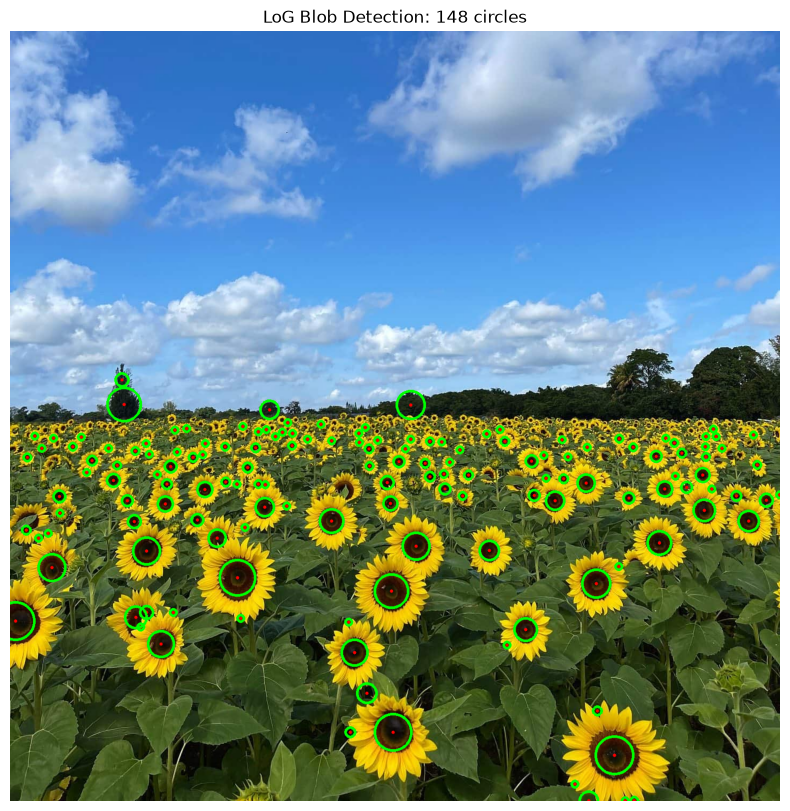

Sigma range used: 4.00 to 25.00 (30 scales)
Largest circles:
  center=(10, 1103), sigma=25.00, radius=35.36
  center=(1130, 1354), sigma=25.00, radius=35.36
  center=(716, 1311), sigma=24.28, radius=34.33
  center=(425, 1022), sigma=23.55, radius=33.31
  center=(213, 698), sigma=22.10, radius=31.26


In [33]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
from scipy.ndimage import gaussian_laplace,maximum_filter


im_1 = cv.imread('images/the_berry_farms_sunflower_field.jpeg')
assert im_1 is not None, "Image not found"
im_1 = cv.cvtColor(im_1, cv.COLOR_BGR2GRAY)
im_1 = im_1.astype(np.float32) / 255.0
print("Image dimensions:", im_1.shape[1], "x", im_1.shape[0])


min_sigma = 4.0
max_sigma = 25.0
num_sigma = 30

sigmas = np.linspace(min_sigma, max_sigma, num_sigma)
responses = []

for sigma in sigmas:
    response = gaussian_laplace(im_1, sigma=sigma)
    normalized_response = (sigma**2) * (response)
    responses.append(normalized_response)

scale_space = np.stack(responses, axis=0)
threshold = 0.6 * scale_space.max()

local_max = maximum_filter(scale_space, size=(5, 5, 5), mode='constant')

peaks = ((scale_space == local_max) & (scale_space > threshold))

sigma_idx, y_coords, x_coords = np.where(peaks)

blobs = []

for si, y, x in zip(sigma_idx, y_coords, x_coords):
    sigma = sigmas[si]
    radius = np.sqrt(2) * sigma

    blobs.append({
        'x': int(x),
        'y': int(y),
        'sigma': float(sigma),
        'radius': float(radius),
        'response': float(scale_space[si, y, x])
    })

im_bgr = cv.imread('images/the_berry_farms_sunflower_field.jpeg')
im_rgb = cv.cvtColor(im_bgr, cv.COLOR_BGR2RGB)

for blob in blobs:
    center = (blob['x'], blob['y'])
    radius = max(1, int(round(blob['radius'])))

    cv.circle(im_rgb, center, radius, (0, 255, 0), 4)
    cv.circle(im_rgb, center, 3, (255, 0, 0), -1)

plt.figure(figsize=(14, 10))
plt.imshow(im_rgb)
plt.title(f'LoG Blob Detection: {len(blobs)} circles')
plt.axis('off')
plt.show()

print(f"Sigma range used: {sigmas[0]:.2f} to {sigmas[-1]:.2f} ({num_sigma} scales)")
print("Largest circles:")
for b in sorted(blobs, key=lambda b: -b['radius'])[:5]:
    print(f"  center=({b['x']}, {b['y']}), sigma={b['sigma']:.2f}, radius={b['radius']:.2f}")


Image size: 360 x 360


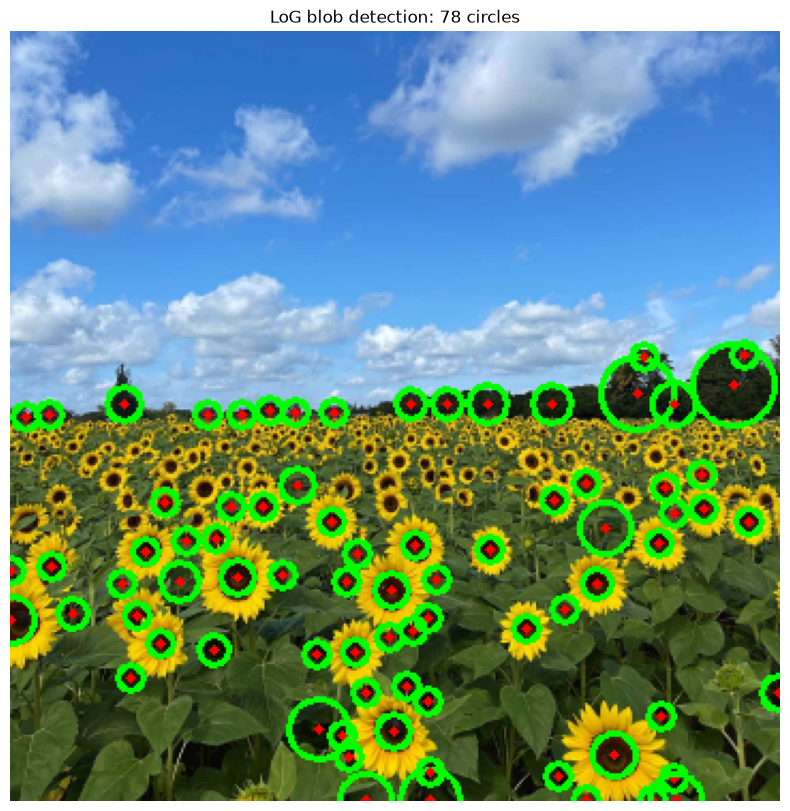

Sigma range used: 4.00 to 18.00 (20 scales)
Largest circles:
  center=(338, 165), sigma=13.11, radius=18.55
  center=(293, 169), sigma=12.12, radius=17.14
  center=(196, 359), sigma=9.56, radius=13.51
  center=(144, 326), sigma=9.56, radius=13.51
  center=(311, 359), sigma=8.83, radius=12.48


In [19]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
from scipy.ndimage import gaussian_laplace, maximum_filter

path = 'images/the_berry_farms_sunflower_field.jpeg'
im_bgr = cv.imread(path, cv.IMREAD_REDUCED_COLOR_4)
assert im_bgr is not None, "Image not found"
im_rgb = cv.cvtColor(im_bgr, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(im_bgr, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0
print("Image size:", gray.shape[1], "x", gray.shape[0])

# --- scale space (geometric spacing) ---
min_sigma, max_sigma, num_sigma = 4.0, 18.0, 20
sigmas = np.geomspace(min_sigma, max_sigma, num_sigma)

# Signed, scale-normalized LoG. Dark blobs (flower centers) -> POSITIVE response
scale_space = np.stack([(s**2) * gaussian_laplace(gray, sigma=s) for s in sigmas])
scale_space[scale_space < 0] = 0          # keep only dark-blob responses

# --- 3D extrema with a window that is larger in space ---
local_max = maximum_filter(scale_space, size=(3, 9, 9), mode='constant')
threshold = 0.35 * scale_space.max()       # tune 0.25–0.5
peaks = (scale_space == local_max) & (scale_space > threshold)

si, ys, xs = np.nonzero(peaks)
cands = [(scale_space[s, y, x], x, y, sigmas[s]) for s, y, x in zip(si, ys, xs)]
cands.sort(reverse=True)                   # strongest first

# --- greedy non-maximum suppression on overlapping circles ---
blobs = []
for resp, x, y, sig in cands:
    r = np.sqrt(2) * sig
    keep = True
    for b in blobs:
        d = np.hypot(x - b['x'], y - b['y'])
        if d < 0.8 * max(r, b['radius']):  # overlaps a stronger blob
            keep = False
            break
    if keep:
        blobs.append(dict(x=int(x), y=int(y), sigma=float(sig),
                          radius=float(r), response=float(resp)))

# --- draw ---
out = im_rgb.copy()
for b in blobs:
    cv.circle(out, (b['x'], b['y']), int(round(b['radius'])), (0, 255, 0), 2)
    cv.circle(out, (b['x'], b['y']), 2, (255, 0, 0), -1)

plt.figure(figsize=(12, 10))
plt.imshow(out)
plt.title(f'LoG blob detection: {len(blobs)} circles')
plt.axis('off')
plt.show()

# --- required report ---
print(f"Sigma range used: {sigmas[0]:.2f} to {sigmas[-1]:.2f} ({num_sigma} scales)")
print("Largest circles:")
for b in sorted(blobs, key=lambda b: -b['radius'])[:5]:
    print(f"  center=({b['x']}, {b['y']}), sigma={b['sigma']:.2f}, radius={b['radius']:.2f}")